<a href="https://colab.research.google.com/github/Niwisha2210/Price-prediction-for-vegetable-and-pulses/blob/main/DSE_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
!pip -q install statsmodels xgboost

import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

warnings.filterwarnings("ignore")

# Settings used by every later cell
H = 7              # forecast horizon in days
TEST_DAYS = 365    # the last 365 days are kept for testing
GATE_FRAC = 0.30   # last 30% of the training period is used to train the gate
SPIKE_THR = 0.15   # a price rise of 15% or more counts as a spike
MIN_OBS = 300      # skip commodities with fewer real observed days than this

print("Setup done")

Setup done


In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, re, glob

DATA_DIR = "/content/drive/MyDrive/csv"     # folder that holds the yearly CSV files (searched recursively)
START_YEAR, END_YEAR = 2018, 2026
STATE_REGEX = None             # None = all-India. For Tamil Nadu use "tamil"

# canonical name: (must match, must NOT match, group)
COMMODITIES = {
    "Tomato": (r"^tomato$",                                   r"", "Vegetable"),
    "Onion":  (r"^onion$",                                    r"", "Vegetable"),
    "Potato": (r"^potato$",                                   r"", "Vegetable"),
    "Tur":    (r"^arhar\s*\(tur/red gram\)\s*\(whole\)",      r"", "Pulse"),
    "Moong":  (r"^green gram\s*\(moong\)\s*\(whole\)",        r"", "Pulse"),
    "Urad":   (r"^black gram\s*\(urd beans\)\s*\(whole\)",    r"", "Pulse"),
    "Chana":  (r"^bengal gram\s*\(gram\)\s*\(whole\)",        r"", "Pulse"),
}
GROUP = {k: v[2] for k, v in COMMODITIES.items()}


def parse_dates(s):
    """Parse a date column whose format is not known in advance, and say what was chosen."""
    s = s.astype(str).str.strip()
    if s.str.match(r"^\d{4}-\d{1,2}-\d{1,2}").mean() > 0.5:
        return pd.to_datetime(s.str[:10], format="%Y-%m-%d", errors="coerce"), "year-month-day"
    p = s.str.extract(r"^(\d{1,2})[/-](\d{1,2})[/-](\d{4})")
    a, b = pd.to_numeric(p[0]), pd.to_numeric(p[1])
    if (a > 12).any() and not (b > 12).any():
        fmt = "%d/%m/%Y"
    elif (b > 12).any() and not (a > 12).any():
        fmt = "%m/%d/%Y"
    else:
        fmt = "%d/%m/%Y"
        print("   WARNING: date order is ambiguous in this file, assuming day/month/year")
    out = pd.to_datetime(p[0] + "/" + p[1] + "/" + p[2], format=fmt, errors="coerce")
    return out, {"%d/%m/%Y": "day/month/year", "%m/%d/%Y": "month/day/year"}[fmt]


def canon(names):
    """Map raw commodity names to our canonical names (others become NaN)."""
    low = names.str.strip().str.lower()
    out = pd.Series(np.nan, index=names.index, dtype=object)
    for k, (inc, exc, _) in COMMODITIES.items():
        m = low.str.contains(inc, regex=True)
        if exc:
            m &= ~low.str.contains(exc, regex=True)
        out[m & out.isna()] = k
    return out


def load_year_file(path):
    want = lambda c: any(k in c.lower() for k in ("state", "market", "commodity", "date", "modal")) and "code" not in c.lower()
    parts = []
    for ch in pd.read_csv(path, usecols=want, chunksize=1_000_000, low_memory=False):
        ch.columns = [c.strip().lower() for c in ch.columns]
        col = lambda key: next(c for c in ch.columns if key in c)
        ch = ch.rename(columns={col("state"): "state", col("market"): "market", col("commodity"): "raw_commodity",
                                col("date"): "date_raw", col("modal"): "price"})
        if STATE_REGEX:
            ch = ch[ch["state"].astype(str).str.contains(STATE_REGEX, case=False, regex=True)]
        ch["commodity"] = canon(ch["raw_commodity"].astype(str))
        ch = ch.dropna(subset=["commodity"])
        ch["price"] = pd.to_numeric(ch["price"], errors="coerce")
        parts.append(ch[ch["price"] > 0])
    return pd.concat(parts) if parts else pd.DataFrame()


files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
files = [f for f in files if START_YEAR <= int((re.findall(r"(20\d\d|19\d\d)", os.path.basename(f)) or [0])[-1]) <= END_YEAR]
print(len(files), "yearly files selected:", [os.path.basename(f) for f in files])

daily, raw_names = [], {}
for f in files:
    d = load_year_file(f)
    if d.empty:
        print(os.path.basename(f), "-> no matching rows"); continue
    d["date"], fmt = parse_dates(d["date_raw"])
    d = d.dropna(subset=["date"])
    med = d.groupby("commodity")["price"].transform("median")
    d = d[(d["price"] < 5 * med) & (d["price"] > med / 5)]            # remove entry errors
    for k, v in d.groupby("commodity")["raw_commodity"].unique().items():
        raw_names.setdefault(k, set()).update(v)
    daily.append(d.groupby(["date", "commodity"]).agg(price=("price", "median"),
                                                      n_markets=("market", "nunique")).reset_index())
    print(f"{os.path.basename(f)}: {len(d):>9,} rows kept | date order {fmt}")

daily = pd.concat(daily).groupby(["date", "commodity"], as_index=False).agg(price=("price", "median"), n_markets=("n_markets", "max"))
print("\nDate range:", daily["date"].min().date(), "to", daily["date"].max().date())
print("\nDistinct days per commodity:")
print(daily.groupby("commodity")["date"].nunique())
print("\nRaw names matched (check these look right):")
for k, v in raw_names.items():
    print(f"  {k}: {sorted(v)[:6]}")

9 yearly files selected: ['2018.csv', '2019.csv', '2020.csv', '2021.csv', '2022.csv', '2023.csv', '2024.csv', '2025.csv', '2026.csv']
2018.csv:   802,306 rows kept | date order year-month-day
2019.csv:   775,722 rows kept | date order year-month-day
2020.csv:   643,242 rows kept | date order year-month-day
2021.csv:   693,201 rows kept | date order year-month-day
2022.csv:   814,563 rows kept | date order year-month-day
2023.csv:   757,793 rows kept | date order year-month-day
2024.csv:   816,177 rows kept | date order year-month-day
2025.csv:   804,884 rows kept | date order year-month-day
2026.csv:    73,414 rows kept | date order year-month-day

Date range: 2018-01-01 to 2026-04-20

Distinct days per commodity:
commodity
Chana     2993
Moong     2988
Onion     3003
Potato    3001
Tomato    3001
Tur       2997
Urad      2990
Name: date, dtype: int64

Raw names matched (check these look right):
  Chana: ['Bengal Gram (Gram)(Whole)']
  Moong: ['Green Gram (Moong)(Whole)']
  Onion: ['On

In [ ]:
def build_panel(daily):
    parts = []
    for c, g in daily.groupby("commodity"):
        d = g.set_index("date")[["price", "n_markets"]].asfreq("D")      # one row per calendar day
        d["obs"] = d["price"].notna()                                    # True = a real observed day
        n_obs = int(d["obs"].sum())
        if n_obs < MIN_OBS:
            print(f"Skipping {c}: only {n_obs} observed days")
            continue
        missing_pct = (~d["obs"]).mean() * 100
        d["price"] = d["price"].interpolate(limit_direction="both")      # fill gaps
        d["arrivals"], d["rain"] = np.nan, np.nan                        # not in this dataset
        d["commodity"], d["group"] = c, GROUP[c]
        parts.append(d)
        print(f"{c:<8} {len(d)} days, {n_obs} observed, {missing_pct:.1f}% filled by interpolation")
    panel = pd.concat(parts)
    panel.index.name = "date"
    return panel

panel = build_panel(daily)
print("\nCommodities kept:", list(panel["commodity"].unique()))
panel.head()

Chana    3032 days, 2993 observed, 1.3% filled by interpolation
Moong    3032 days, 2988 observed, 1.5% filled by interpolation
Onion    3032 days, 3003 observed, 1.0% filled by interpolation
Potato   3032 days, 3001 observed, 1.0% filled by interpolation
Tomato   3032 days, 3001 observed, 1.0% filled by interpolation
Tur      3032 days, 2997 observed, 1.2% filled by interpolation
Urad     3032 days, 2990 observed, 1.4% filled by interpolation

Commodities kept: ['Chana', 'Moong', 'Onion', 'Potato', 'Tomato', 'Tur', 'Urad']


,price,n_markets,obs,arrivals,rain,commodity,group
date,,,,,,,
2018-01-01,3969.5,241.0,True,NaN,NaN,Chana,Pulse
2018-01-02,3919.0,251.0,True,NaN,NaN,Chana,Pulse
2018-01-03,3918.0,252.0,True,NaN,NaN,Chana,Pulse
2018-01-04,3900.0,265.0,True,NaN,NaN,Chana,Pulse
2018-01-05,3900.0,296.0,True,NaN,NaN,Chana,Pulse


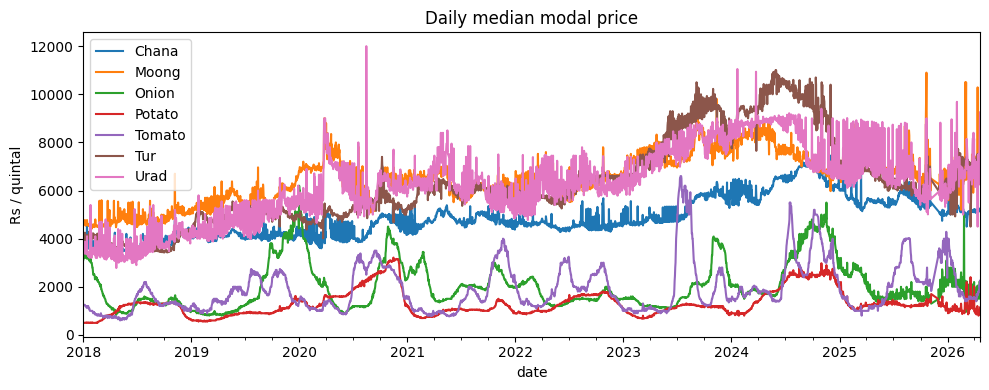

Volatility (std of 7-day log change):
            group  volatility
Chana       Pulse       0.053
Moong       Pulse       0.054
Onion   Vegetable       0.088
Potato  Vegetable       0.072
Tomato  Vegetable       0.123
Tur         Pulse       0.044
Urad        Pulse       0.091


In [ ]:
os.makedirs("figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 4))
for c, g in panel.groupby("commodity"):
    g["price"].plot(ax=ax, label=c)
ax.set_ylabel("Rs / quintal")
ax.set_title("Daily median modal price")
ax.legend()
plt.tight_layout()
plt.savefig("figures/price_history.png", dpi=130)
plt.show()

# how jumpy is each commodity? (std of 7-day log price change, observed days only)
vol = {}
for c, g in panel.groupby("commodity"):
    ch = np.log(g["price"]).diff(7)[g["obs"] & g["obs"].shift(7, fill_value=False)]
    vol[c] = ch.std()
grp = panel.groupby("commodity")["group"].first()
print("Volatility (std of 7-day log change):")
print(pd.DataFrame({"group": grp, "volatility": pd.Series(vol)}).round(3))

In [ ]:
def make_features(p, H):
    lp = np.log(p["price"])
    r1 = lp.diff()
    f = pd.DataFrame(index=p.index)

    for k in (1, 7, 14, 28):                       # past price changes
        f[f"ret_{k}"] = lp - lp.shift(k)
    for w in (7, 14, 30):                          # recent volatility
        f[f"vol_{w}"] = r1.rolling(w).std()
    f["vol_ratio"] = f["vol_7"] / (f["vol_30"] + 1e-9)
    f["ma7_gap"] = lp - lp.rolling(7).mean()       # price vs recent averages
    f["ma30_gap"] = lp - lp.rolling(30).mean()
    f["month_sin"] = np.sin(2 * np.pi * p.index.month / 12)
    f["month_cos"] = np.cos(2 * np.pi * p.index.month / 12)

    if p["arrivals"].notna().any():
        la = np.log(p["arrivals"] + 1)
        f["arrivals_gap"] = la - la.rolling(30).mean()
    if p["rain"].notna().any():
        for w in (7, 14, 30):
            f[f"rain_{w}"] = p["rain"].rolling(w).sum()

    f["is_pulse"] = float(p["group"].iloc[0] == "Pulse")   # 1 for pulses, 0 for vegetables

    f["price"], f["commodity"], f["group"] = p["price"], p["commodity"], p["group"]
    f["y_price"] = p["price"].shift(-H)            # price H days ahead
    f["y_ret"] = lp.shift(-H) - lp                 # log change over next H days
    fut_max = p["price"][::-1].rolling(H).max()[::-1].shift(-1)
    f["fut_max_rise"] = fut_max / p["price"] - 1
    # use a row only if today AND the target day are real observations
    f["obs_pair"] = p["obs"] & p["obs"].shift(-H, fill_value=False)
    return f

META = ["price", "commodity", "group", "y_ret", "y_price", "fut_max_rise", "obs_pair"]

def feature_columns(feat):
    return [c for c in feat.columns if c not in META and feat[c].notna().any()]

feat = pd.concat([make_features(g, H) for _, g in panel.groupby("commodity")])
fcols = feature_columns(feat)

lp_by_c = {c: np.log(g["price"]) for c, g in panel.groupby("commodity")}
end_by_c = {c: g.index.max() for c, g in panel.groupby("commodity")}

print("Features used:", fcols)
print("Rows:", len(feat), "| rows with real start and target day:", int(feat["obs_pair"].sum()))

Features used: ['ret_1', 'ret_7', 'ret_14', 'ret_28', 'vol_7', 'vol_14', 'vol_30', 'vol_ratio', 'ma7_gap', 'ma30_gap', 'month_sin', 'month_cos', 'is_pulse']
Rows: 21224 | rows with real start and target day: 20802


In [ ]:
Htd = pd.Timedelta(days=H)

start, d_end = feat.index.min(), feat.index.max()
train_end = (d_end - pd.Timedelta(days=TEST_DAYS)).normalize()
fit_end = (start + (train_end - start) * (1 - GATE_FRAC)).normalize()

print("Experts are trained on data up to:", fit_end.date())
print("Gate is trained on forecasts from:", (fit_end + pd.Timedelta(days=1)).date(), "to", train_end.date())
print("Test period:", (train_end + pd.Timedelta(days=1)).date(), "to", d_end.date())

# keep only rows that have all inputs, targets, and real observed days
ok = lambda x: x[x["obs_pair"]].dropna(subset=fcols + ["y_ret", "y_price"])

# keep every n-th forecast date per commodity
def thin(x, step):
    return x[x.groupby("commodity").cumcount() % step == 0]

Experts are trained on data up to: 2023-02-10
Gate is trained on forecasts from: 2023-02-11 to 2025-04-20
Test period: 2025-04-21 to 2026-04-20


In [ ]:
def fourier(idx, K=2):                      # yearly seasonality terms for SARIMA
    doy = np.asarray(idx.dayofyear)
    cols = []
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * doy / 365.25), np.cos(2 * np.pi * k * doy / 365.25)]
    return np.column_stack(cols)

def fit_sarima(lp):
    return SARIMAX(lp, exog=fourier(lp.index), order=(1, 1, 1)).fit(disp=False)

def sarima_rolling(lp, fit_to, seg_end, origins, H):
    """Fit on data up to fit_to, then forecast H days ahead from each origin date."""
    train = lp[:fit_to]
    seg = lp[fit_to + pd.Timedelta(days=1): seg_end]
    ext = fit_sarima(train).extend(seg, exog=fourier(seg.index))
    out = {}
    for d, o in zip(origins, seg.index.get_indexer(origins)):
        pr = ext.get_prediction(start=o + 1, end=o + H, dynamic=0).predicted_mean
        out[d] = float(np.exp(pr.iloc[-1]))
    return pd.Series(out)

def sarima_for_rows(rows, fit_to, seg_end_by_c, H):
    preds = []
    for c, g in rows.groupby("commodity"):
        try:
            s = sarima_rolling(lp_by_c[c], fit_to, seg_end_by_c[c], g.index, H)
            preds.append(pd.DataFrame({"commodity": c, "sarima": s.values}, index=s.index))
        except Exception as e:
            print(f"SARIMA failed for {c}: {e}")
    sp = pd.concat(preds)
    rows = rows.reset_index().merge(sp.reset_index().rename(columns={"index": "date"}),
                                    on=["date", "commodity"], how="inner")
    return rows.set_index("date")

def make_xgb():
    return XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
                        colsample_bytree=0.8, min_child_weight=5, reg_lambda=2.0,
                        random_state=42, n_jobs=2)

# Stage 1: XGBoost trained on the first part of the training data only
tr1 = ok(feat[feat.index <= fit_end - Htd])
xgb1 = make_xgb().fit(tr1[fcols], tr1["y_ret"])

# Forecasts from both experts for the gate-training period (every 3rd row)
g = thin(ok(feat[(feat.index > fit_end) & (feat.index <= train_end - Htd)]), 3)
g["xgboost"] = g["price"] * np.exp(xgb1.predict(g[fcols]))
g = sarima_for_rows(g, fit_end, {c: train_end for c in end_by_c}, H)

# Label: 1 if XGBoost was closer to the real price than SARIMA
g["xgb_better"] = ((g["xgboost"] - g["y_price"]).abs() <
                   (g["sarima"] - g["y_price"]).abs()).astype(int)

print("Gate training rows:", len(g))
print(f"XGBoost was closer than SARIMA on {g['xgb_better'].mean():.0%} of them")
g[["commodity", "price", "y_price", "sarima", "xgboost", "xgb_better"]].head()

Gate training rows: 1853
XGBoost was closer than SARIMA on 57% of them


,commodity,price,y_price,sarima,xgboost,xgb_better
date,,,,,,
2023-02-11,Chana,4581.0,5345.0,4597.699285,4598.418880,1
2023-02-14,Chana,4598.0,4552.5,4613.729398,4611.795193,1
2023-02-17,Chana,4605.0,4575.0,4613.552222,4627.776300,0
2023-02-20,Chana,4600.0,4624.5,4712.144225,4632.833219,1
2023-02-23,Chana,4551.0,4630.5,4643.174817,4585.174513,0


In [ ]:
GATE_COLS = ["vol_14", "vol_30", "month_sin", "month_cos"]

class ConstantGate:
    """Fallback if one expert was better on every single row."""
    def __init__(self, p): self.p = float(p)
    def predict_proba(self, X):
        n = len(X)
        return np.column_stack([np.full(n, 1 - self.p), np.full(n, self.p)])

if g["xgb_better"].nunique() < 2:
    gate = ConstantGate(g["xgb_better"].iloc[0])
    print("Only one class in the gate labels, using a constant gate")
else:
    gate = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000))
    gate.fit(g[GATE_COLS], g["xgb_better"])
    coef = pd.DataFrame({"feature": GATE_COLS,
                         "coefficient": gate.named_steps["logisticregression"].coef_[0]})
    print("Gate coefficients (standardised):")
    display(coef.round(3))

Gate coefficients (standardised):


,feature,coefficient
0,vol_14,0.037
1,vol_30,0.071
2,month_sin,-0.053
3,month_cos,-0.041


In [ ]:
# Stage 2: refit on all training data, forecast the untouched test period
tr2 = ok(feat[feat.index <= train_end - Htd])
xgb2 = make_xgb().fit(tr2[fcols], tr2["y_ret"])

t = thin(ok(feat[feat.index > train_end]), 3)        # every 3rd usable forecast date
t["xgboost"] = t["price"] * np.exp(xgb2.predict(t[fcols]))
t = sarima_for_rows(t, train_end, end_by_c, H)
t["weight_xgb"] = gate.predict_proba(t[GATE_COLS])[:, 1]
t["naive"] = t["price"]                               # baseline: price stays the same
t["blend50"] = 0.5 * t["xgboost"] + 0.5 * t["sarima"]
t["hybrid"] = t["weight_xgb"] * t["xgboost"] + (1 - t["weight_xgb"]) * t["sarima"]

rf_reg = RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5,
                               n_jobs=-1, random_state=42).fit(tr2[fcols], tr2["y_ret"])
t["random_forest"] = t["price"] * np.exp(rf_reg.predict(t[fcols]))

MODELS = ["naive", "sarima", "xgboost", "random_forest", "blend50", "hybrid"]
LABEL = {"naive": "Naive", "sarima": "SARIMA", "xgboost": "XGBoost",
         "random_forest": "Random Forest", "blend50": "50/50 blend",
         "hybrid": "Gated hybrid (VG-HF)"}
order = [LABEL[m] for m in MODELS]

rows = []
for c, d in t.groupby("commodity"):
    for m in MODELS:
        e = d[m] - d["y_price"]
        rows.append(dict(commodity=c, model=LABEL[m], MAE=e.abs().mean(),
                         RMSE=np.sqrt((e ** 2).mean()),
                         MAPE=(e.abs() / d["y_price"]).mean() * 100))
by_c = pd.DataFrame(rows)
overall = by_c.groupby("model")[["MAE", "RMSE", "MAPE"]].mean().loc[order]

print("Test forecasts:", len(t), "| per commodity:", t["commodity"].value_counts().to_dict())
print("\nMAPE (%) per commodity, lower is better:")
display(by_c.pivot(index="model", columns="commodity", values="MAPE").loc[order].round(2))
print("All commodities, all three metrics:")
display(overall.round(2))

Test forecasts: 723 | per commodity: {'Onion': 105, 'Urad': 105, 'Chana': 104, 'Tomato': 104, 'Potato': 104, 'Tur': 103, 'Moong': 98}

MAPE (%) per commodity, lower is better:


commodity,Chana,Moong,Onion,Potato,Tomato,Tur,Urad
model,,,,,,,
Naive,7.52,5.20,9.01,8.30,9.55,4.29,6.01
SARIMA,8.37,5.53,9.05,7.94,8.46,4.57,5.75
XGBoost,7.55,5.38,9.19,8.91,8.44,4.31,5.26
Random Forest,7.39,5.30,8.96,8.96,8.63,4.22,5.44
50/50 blend,7.84,5.28,9.04,8.19,8.28,4.33,5.29
Gated hybrid (VG-HF),7.71,5.26,9.08,8.37,8.29,4.30,5.27


All commodities, all three metrics:


,MAE,RMSE,MAPE
model,,,
Naive,223.81,417.37,7.13
SARIMA,230.65,386.39,7.10
XGBoost,220.74,407.06,7.00
Random Forest,219.18,399.65,6.99
50/50 blend,220.34,388.62,6.89
Gated hybrid (VG-HF),219.32,391.33,6.90


In [ ]:
def make_rf():
    return RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=5,
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=42)

use = feat[feat["obs_pair"]].dropna(subset=fcols + ["fut_max_rise"])
sp_tr, sp_te = use[use.index <= train_end - Htd], use[use.index > train_end]
y_tr = (sp_tr["fut_max_rise"] >= SPIKE_THR).astype(int)
y_te = (sp_te["fut_max_rise"] >= SPIKE_THR).astype(int)

rf = make_rf().fit(sp_tr[fcols], y_tr)
p_te = rf.predict_proba(sp_te[fcols])[:, 1]
pred = (p_te >= 0.5).astype(int)

spike_res = {
    "test rows": len(y_te),
    "share of days that were spikes": round(float(y_te.mean()), 3),
    "precision": round(float(precision_score(y_te, pred, zero_division=0)), 3),
    "recall": round(float(recall_score(y_te, pred, zero_division=0)), 3),
    "F1": round(float(f1_score(y_te, pred, zero_division=0)), 3),
}
if 0 < y_te.sum() < len(y_te):
    spike_res["ROC-AUC"] = round(float(roc_auc_score(y_te, p_te)), 3)
    spike_res["PR-AUC"] = round(float(average_precision_score(y_te, p_te)), 3)

print(f"Spike = price rises {SPIKE_THR:.0%} or more within the next {H} days")
pd.Series(spike_res)

Spike = price rises 15% or more within the next 7 days


,0
test rows,2166.000
share of days that were spikes,0.199
precision,0.400
recall,0.594
F1,0.478
ROC-AUC,0.758
PR-AUC,0.456


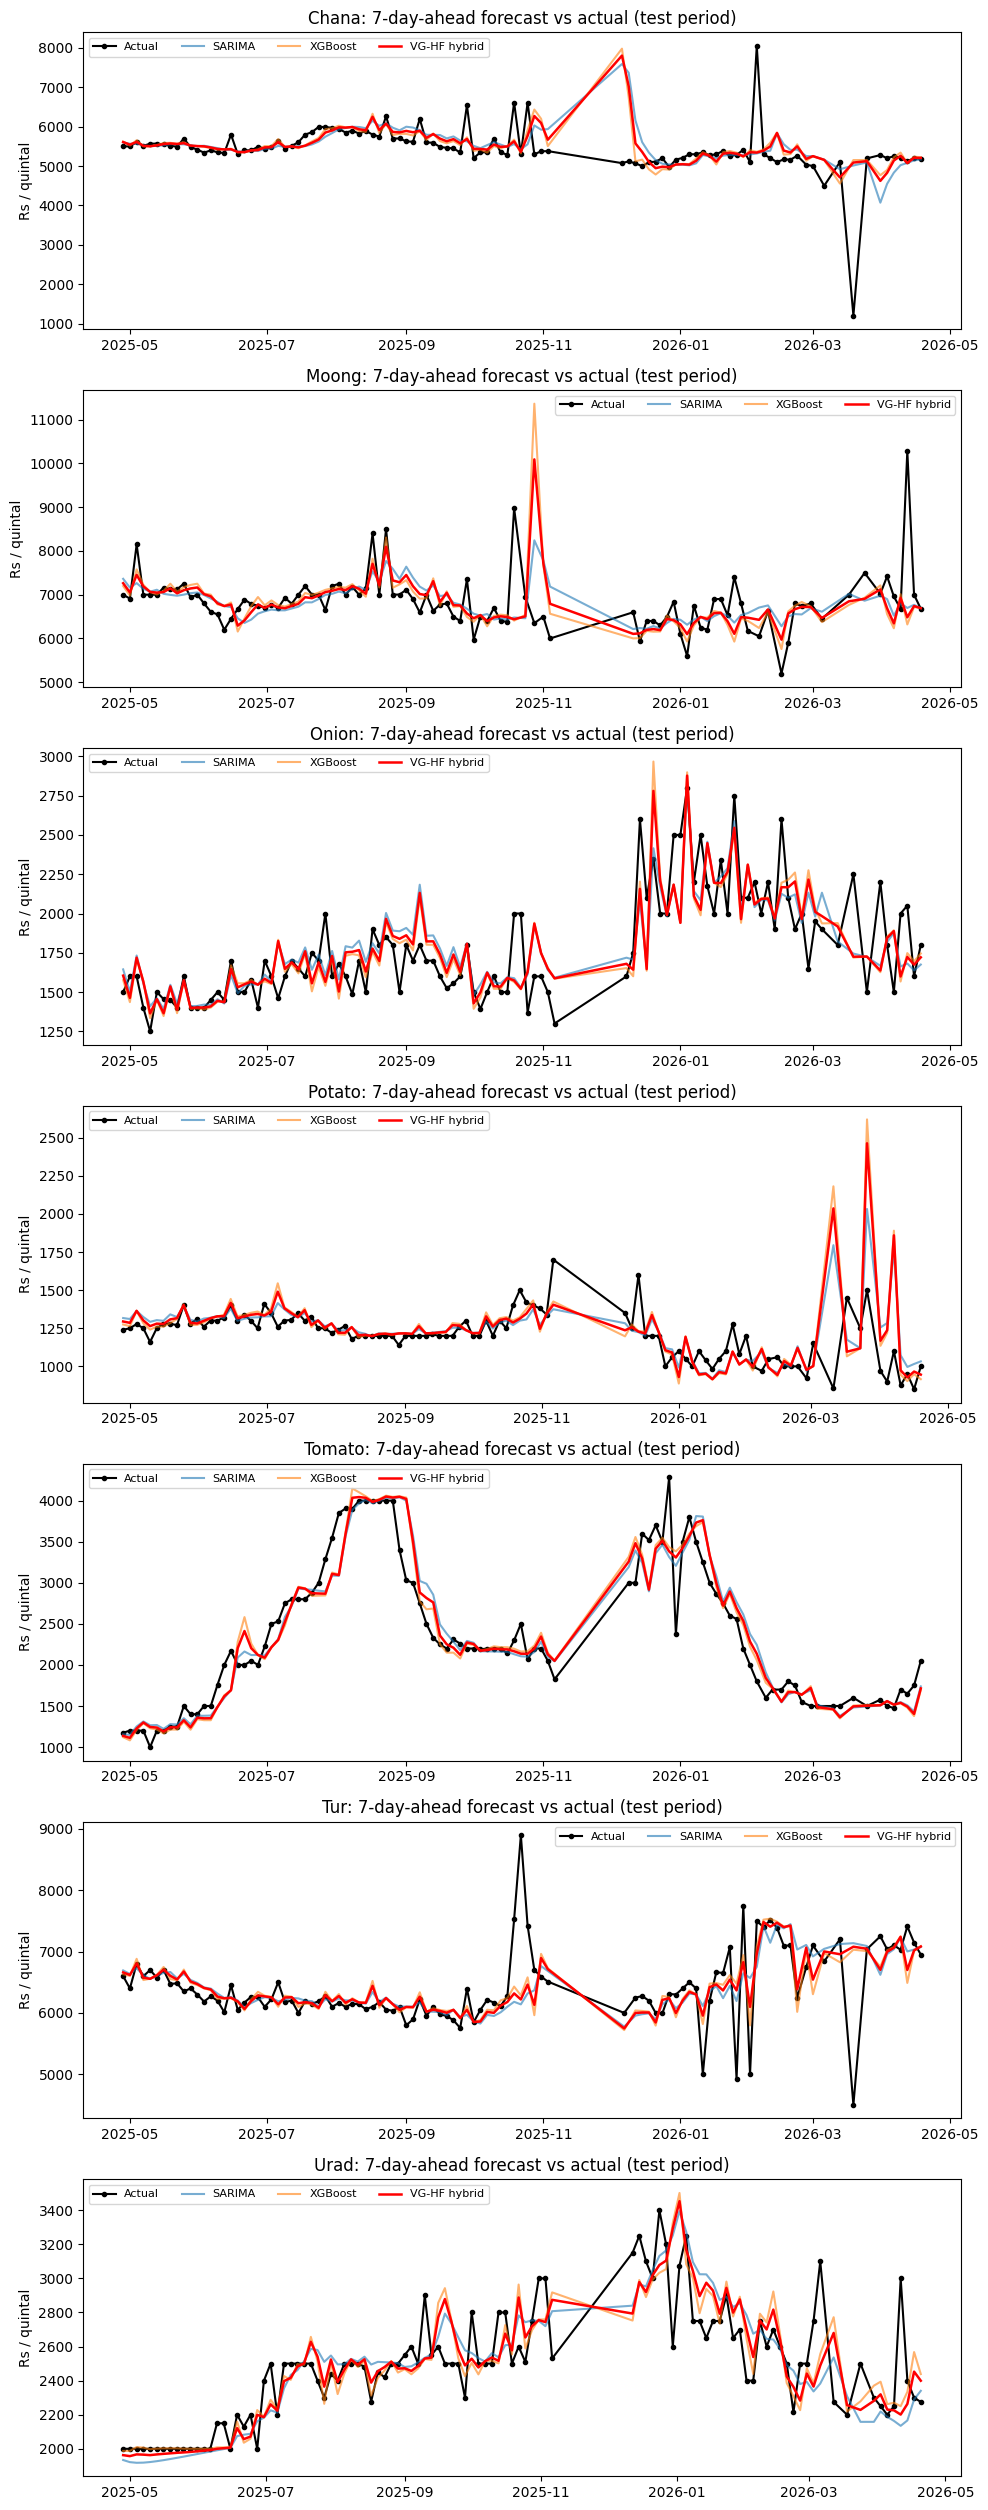

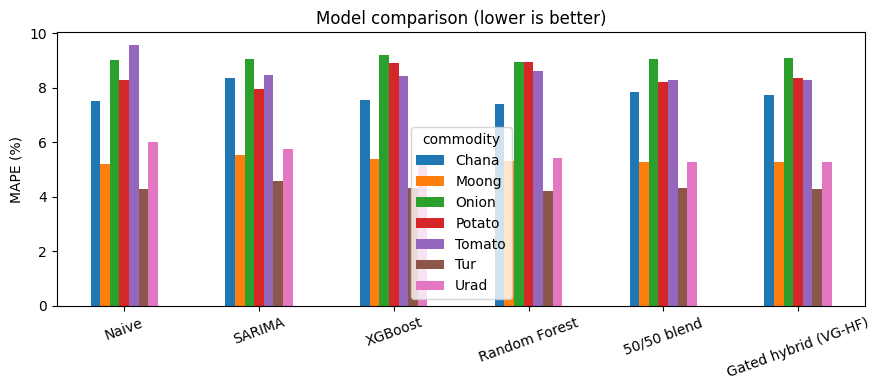

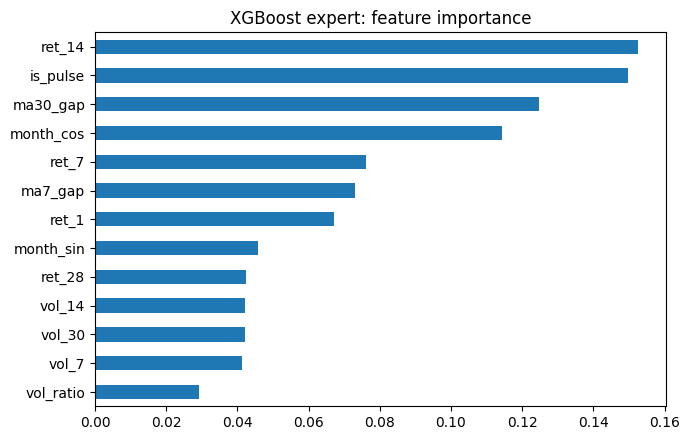

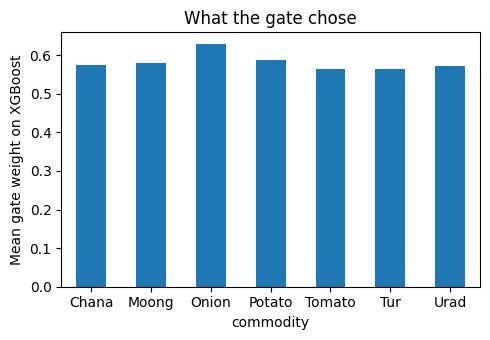

Charts saved in the figures/ folder (left sidebar -> Files) for your report.


In [ ]:
# 1) Forecast vs actual for each commodity
cs = list(t["commodity"].unique())
fig, axs = plt.subplots(len(cs), 1, figsize=(10, 3.6 * len(cs)), squeeze=False)
for ax, c in zip(axs[:, 0], cs):
    dd = t[t["commodity"] == c]
    x = dd.index + Htd                               # date the forecast is for
    ax.plot(x, dd["y_price"], "k.-", label="Actual")
    ax.plot(x, dd["sarima"], alpha=0.6, label="SARIMA")
    ax.plot(x, dd["xgboost"], alpha=0.6, label="XGBoost")
    ax.plot(x, dd["hybrid"], "r-", lw=1.8, label="VG-HF hybrid")
    ax.set_title(f"{c}: {H}-day-ahead forecast vs actual (test period)")
    ax.set_ylabel("Rs / quintal")
    ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.savefig("figures/forecast_vs_actual.png", dpi=130)
plt.show()

# 2) Model comparison
ax = by_c.pivot(index="model", columns="commodity", values="MAPE").loc[order].plot.bar(figsize=(9, 4), rot=20)
ax.set_ylabel("MAPE (%)")
ax.set_xlabel("")
ax.set_title("Model comparison (lower is better)")
plt.tight_layout()
plt.savefig("figures/model_comparison.png", dpi=130)
plt.show()

# 3) What the XGBoost expert relies on
pd.Series(xgb2.feature_importances_, index=fcols).sort_values().plot.barh(figsize=(7, 4.5))
plt.title("XGBoost expert: feature importance")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=130)
plt.show()

# 4) What the gate chose
gw = t.groupby("commodity")["weight_xgb"].mean()
gw.plot.bar(figsize=(5, 3.5), rot=0)
plt.ylabel("Mean gate weight on XGBoost")
plt.title("What the gate chose")
plt.tight_layout()
plt.savefig("figures/gate_weights.png", dpi=130)
plt.show()

print("Charts saved in the figures/ folder (left sidebar -> Files) for your report.")

Pooled block-bootstrap 95% CI (negative = hybrid better; significant if CI excludes 0):


,comparison,mean_diff_MAPE_pts,CI_low,CI_high,significant
0,Gated hybrid (VG-HF) vs Naive,-0.661,-1.162,-0.201,True
1,Gated hybrid (VG-HF) vs 50/50 blend,0.064,-0.084,0.230,False
2,Gated hybrid (VG-HF) vs SARIMA,-0.012,-0.561,0.622,False
3,Gated hybrid (VG-HF) vs XGBoost,-0.258,-0.600,0.026,False



Diebold-Mariano p-values per commodity (p < 0.05 = significant difference):


comparison,hybrid vs blend50,hybrid vs naive,hybrid vs sarima,hybrid vs xgboost
commodity,,,,
Chana,0.058,0.555,0.019,0.366
Moong,0.722,0.831,0.451,0.615
Onion,0.545,0.824,0.924,0.455
Potato,0.092,0.881,0.321,0.013
Tomato,0.836,0.039,0.622,0.567
Tur,0.343,0.958,0.139,0.964
Urad,0.568,0.097,0.042,0.950



Best fixed weight on gate-training period: w_xgb = 0.85

Gate vs fixed weights vs oracle:


,MAPE (%)
Naive,7.148
SARIMA,7.114
XGBoost,7.022
Fixed 50/50,6.912
Fixed tuned (w=0.85),6.961
Gated hybrid (VG-HF),6.915
Oracle (upper bound),5.754



MAPE (%) by volatility regime:


,High volatility,Low volatility
Naive,8.584,5.699
SARIMA,8.442,5.776
XGBoost,8.378,5.655
Fixed 50/50,8.228,5.584
Fixed tuned (w=0.85),8.299,5.612
Gated hybrid (VG-HF),8.237,5.583
Oracle (upper bound),6.722,4.778


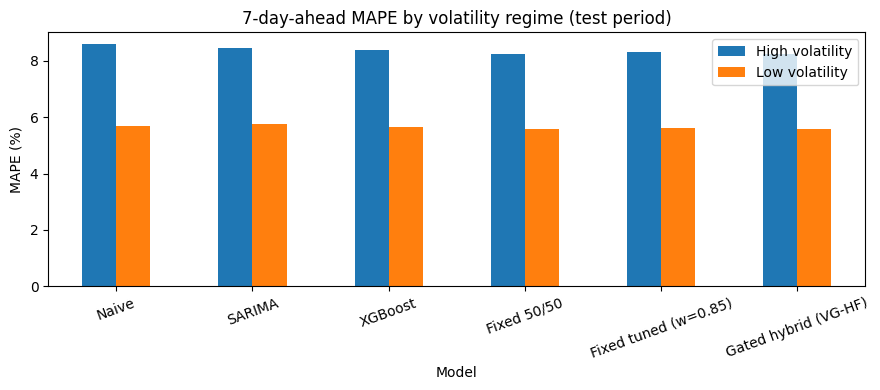

In [ ]:
from scipy.stats import norm
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)

T = t.sort_index().copy()
ape = lambda p, y: (p - y).abs() / y          # absolute percentage error per row

# ---------- 1) Significance: Diebold-Mariano (per commodity) + block-bootstrap CI (pooled) ----------
def dm_test(a, b, lag=2):
    """Diebold-Mariano on APE with Newey-West variance. stat < 0 means model a is better."""
    d = (a - b).values; n = len(d); dc = d - d.mean()
    var = np.sum(dc * dc) / n
    for k in range(1, lag + 1):
        var += 2 * (1 - k / (lag + 1)) * np.sum(dc[k:] * dc[:-k]) / n
    stat = d.mean() / np.sqrt(var / n)
    return stat, 2 * (1 - norm.cdf(abs(stat)))

def boot_ci(a, b, n_boot=2000, block=3, seed=42):
    """Moving-block bootstrap of mean APE difference (in % points), pooled over commodities."""
    rng = np.random.default_rng(seed)
    d = ((ape(T[a], T["y_price"]) - ape(T[b], T["y_price"])) * 100).groupby(level=0).mean().sort_index().values
    n = len(d); nb = int(np.ceil(n / block)); means = []
    for _ in range(n_boot):
        s = rng.integers(0, n - block + 1, nb)
        means.append(np.concatenate([d[i:i + block] for i in s])[:n].mean())
    lo, hi = np.percentile(means, [2.5, 97.5])
    return d.mean(), lo, hi

pairs = [("hybrid", "naive"), ("hybrid", "blend50"), ("hybrid", "sarima"), ("hybrid", "xgboost")]

rows_sig = []
for a, b in pairs:
    m, lo, hi = boot_ci(a, b)
    rows_sig.append(dict(comparison=f"{LABEL[a]} vs {LABEL[b]}", mean_diff_MAPE_pts=round(m, 3),
                         CI_low=round(lo, 3), CI_high=round(hi, 3),
                         significant=bool(lo > 0 or hi < 0)))
sig_pooled = pd.DataFrame(rows_sig)
print("Pooled block-bootstrap 95% CI (negative = hybrid better; significant if CI excludes 0):")
display(sig_pooled)

rows_dm = []
for c, d in T.groupby("commodity"):
    for a, b in pairs:
        stat, p = dm_test(ape(d[a], d["y_price"]), ape(d[b], d["y_price"]))
        rows_dm.append(dict(commodity=c, comparison=f"hybrid vs {b}", DM_stat=round(stat, 2), p_value=round(p, 3)))
sig_dm = pd.DataFrame(rows_dm).pivot(index="commodity", columns="comparison", values="p_value")
print("\nDiebold-Mariano p-values per commodity (p < 0.05 = significant difference):")
display(sig_dm)

# ---------- 2) Gate vs oracle vs fixed weight ----------
ws = np.linspace(0, 1, 21)
w_star = ws[int(np.argmin([ape(w * g["xgboost"] + (1 - w) * g["sarima"], g["y_price"]).mean() for w in ws]))]
print(f"\nBest fixed weight on gate-training period: w_xgb = {w_star:.2f}")

T["fixed_tuned"] = w_star * T["xgboost"] + (1 - w_star) * T["sarima"]
T["oracle"] = np.where((T["xgboost"] - T["y_price"]).abs() <= (T["sarima"] - T["y_price"]).abs(),
                       T["xgboost"], T["sarima"])

GATE_MODELS = {"naive": "Naive", "sarima": "SARIMA", "xgboost": "XGBoost", "blend50": "Fixed 50/50",
               "fixed_tuned": f"Fixed tuned (w={w_star:.2f})", "hybrid": "Gated hybrid (VG-HF)",
               "oracle": "Oracle (upper bound)"}
gate_tbl = pd.Series({v: ape(T[k], T["y_price"]).mean() * 100 for k, v in GATE_MODELS.items()},
                     name="MAPE (%)").round(3).to_frame()
print("\nGate vs fixed weights vs oracle:")
display(gate_tbl)

# ---------- 3) MAPE by volatility regime (median split of vol_30 within each commodity) ----------
T["regime"] = np.where(T["vol_30"] >= T.groupby("commodity")["vol_30"].transform("median"),
                       "High volatility", "Low volatility")
reg = pd.DataFrame({v: T.groupby("regime").apply(lambda d, k=k: ape(d[k], d["y_price"]).mean() * 100)
                    for k, v in GATE_MODELS.items()}).T.round(3)
reg.columns.name = None
print("\nMAPE (%) by volatility regime:")
display(reg)

ax = reg.drop(index="Oracle (upper bound)").plot.bar(figsize=(9, 4), rot=20)
ax.set_ylabel("MAPE (%)"); ax.set_xlabel("Model")
ax.set_title("7-day-ahead MAPE by volatility regime (test period)")
plt.tight_layout(); plt.savefig("figures/regime_mape.png", dpi=130); plt.show()

sig_pooled.to_csv("results/significance_bootstrap.csv", index=False)
sig_dm.to_csv("results/significance_dm_by_commodity.csv")
gate_tbl.to_csv("results/gate_vs_oracle.csv"); reg.to_csv("results/mape_by_regime.csv")

Spike = rise >= 15% within 7 days | spike share in test: 0.199


,precision,recall,F1,ROC_AUC,PR_AUC
model,,,,,
Random Forest,0.400,0.594,0.478,0.758,0.456
Logistic Regression,0.330,0.712,0.451,0.726,0.390
Rule: ret_7 >= 0.076,0.187,0.123,0.148,0.416,0.176
Always predict spike,0.199,1.000,0.332,0.500,0.199
Never predict spike,0.000,0.000,0.000,0.500,0.199


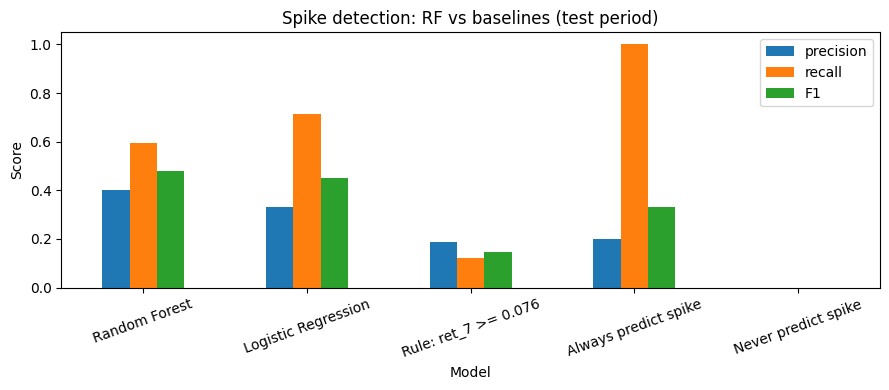

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

def spike_row(name, y, score, pred):
    return dict(model=name,
                precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0),
                F1=f1_score(y, pred, zero_division=0),
                ROC_AUC=roc_auc_score(y, score),
                PR_AUC=average_precision_score(y, score))

res = []

# Random Forest (your model, from cell 12)
res.append(spike_row("Random Forest", y_te, p_te, (p_te >= 0.5).astype(int)))

# Logistic Regression on the same features
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(sp_tr[fcols], y_tr)
p_lr = lr.predict_proba(sp_te[fcols])[:, 1]
res.append(spike_row("Logistic Regression", y_te, p_lr, (p_lr >= 0.5).astype(int)))

# Rule: predict spike if ret_7 >= threshold (threshold chosen on the training period for best F1)
cands = np.nanquantile(sp_tr["ret_7"], np.linspace(0.5, 0.95, 19))
best_thr = max(cands, key=lambda th: f1_score(y_tr, (sp_tr["ret_7"] >= th).astype(int), zero_division=0))
res.append(spike_row(f"Rule: ret_7 >= {best_thr:.3f}", y_te, sp_te["ret_7"].values,
                     (sp_te["ret_7"] >= best_thr).astype(int)))

# Trivial baselines
res.append(spike_row("Always predict spike", y_te, np.zeros(len(y_te)), np.ones(len(y_te), dtype=int)))
res.append(spike_row("Never predict spike", y_te, np.zeros(len(y_te)), np.zeros(len(y_te), dtype=int)))

spike_tbl = pd.DataFrame(res).set_index("model").round(3)
print(f"Spike = rise >= {SPIKE_THR:.0%} within {H} days | spike share in test: {y_te.mean():.3f}")
display(spike_tbl)
spike_tbl.to_csv("results/spike_baselines.csv")

ax = spike_tbl[["precision", "recall", "F1"]].plot.bar(figsize=(9, 4), rot=20)
ax.set_ylabel("Score"); ax.set_xlabel("Model"); ax.set_title("Spike detection: RF vs baselines (test period)")
plt.tight_layout(); plt.savefig("figures/spike_baselines.png", dpi=130); plt.show()

fold 1 done (217 forecasts)
fold 2 done (216 forecasts)
fold 3 done (143 forecasts)
fold 4 done (161 forecasts)

Rolling-origin MAPE (%) per window:


fold,F1: 2025-04-21 to 2025-07-20,F2: 2025-07-21 to 2025-10-19,F3: 2025-10-20 to 2026-01-18,F4: 2026-01-19 to 2026-04-19,Mean,Std
model,,,,,,
Naive,3.79,5.01,8.37,13.43,7.65,4.31
SARIMA,4.02,5.29,8.24,12.16,7.43,3.61
XGBoost,3.98,4.87,8.63,11.88,7.34,3.63
Random Forest,3.97,4.78,8.49,12.12,7.34,3.74
50/50 blend,3.82,4.89,8.24,11.85,7.20,3.63
Gated hybrid (VG-HF),3.85,4.86,8.29,11.76,7.19,3.59


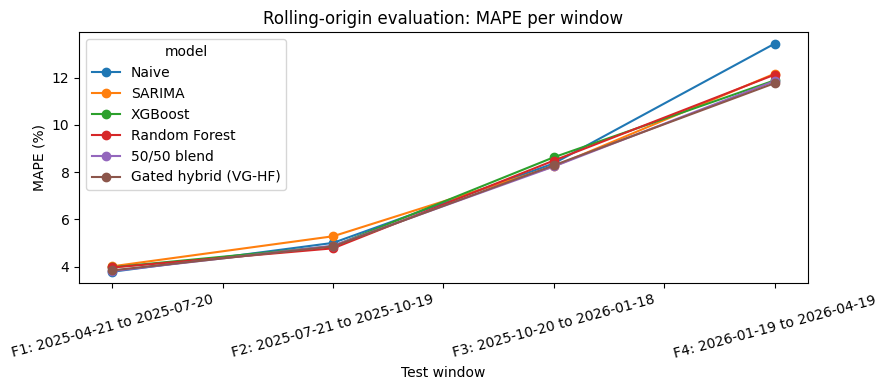

In [ ]:
N_FOLDS, FOLD_DAYS = 4, 91
fold_rows = []

for k in range(N_FOLDS):
    cut = train_end + pd.Timedelta(days=k * FOLD_DAYS)          # train on data up to here
    end = min(cut + pd.Timedelta(days=FOLD_DAYS), d_end)        # test on the next ~91 days
    tr_k = ok(feat[feat.index <= cut - Htd])                    # targets must be known by 'cut'
    te_k = thin(ok(feat[(feat.index > cut) & (feat.index <= end)]), 3).copy()
    if len(te_k) == 0:
        continue

    xgb_k = make_xgb().fit(tr_k[fcols], tr_k["y_ret"])
    rf_k = RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                 n_jobs=-1, random_state=42).fit(tr_k[fcols], tr_k["y_ret"])
    te_k["xgboost"] = te_k["price"] * np.exp(xgb_k.predict(te_k[fcols]))
    te_k["random_forest"] = te_k["price"] * np.exp(rf_k.predict(te_k[fcols]))
    te_k = sarima_for_rows(te_k, cut, end_by_c, H)
    te_k["weight_xgb"] = gate.predict_proba(te_k[GATE_COLS])[:, 1]
    te_k["naive"] = te_k["price"]
    te_k["blend50"] = 0.5 * te_k["xgboost"] + 0.5 * te_k["sarima"]
    te_k["hybrid"] = te_k["weight_xgb"] * te_k["xgboost"] + (1 - te_k["weight_xgb"]) * te_k["sarima"]

    for m in MODELS:
        fold_rows.append(dict(fold=f"F{k+1}: {(cut + pd.Timedelta(days=1)).date()} to {end.date()}",
                              model=LABEL[m], MAPE=ape(te_k[m], te_k["y_price"]).mean() * 100,
                              n=len(te_k)))
    print(f"fold {k+1} done ({len(te_k)} forecasts)")

roll = pd.DataFrame(fold_rows)
roll_tbl = roll.pivot(index="model", columns="fold", values="MAPE").loc[order]
roll_tbl["Mean"] = roll_tbl.mean(axis=1)
roll_tbl["Std"] = roll_tbl.drop(columns="Mean").std(axis=1)
roll_tbl = roll_tbl.round(2)
print("\nRolling-origin MAPE (%) per window:")
display(roll_tbl)
roll_tbl.to_csv("results/rolling_origin_mape.csv")

ax = roll_tbl.drop(columns=["Mean", "Std"]).T.plot(marker="o", figsize=(9, 4))
ax.set_ylabel("MAPE (%)"); ax.set_xlabel("Test window"); ax.set_title("Rolling-origin evaluation: MAPE per window")
plt.xticks(rotation=15); plt.tight_layout(); plt.savefig("figures/rolling_origin.png", dpi=130); plt.show()

In [ ]:
import joblib
os.makedirs("artifacts", exist_ok=True)
os.makedirs("results", exist_ok=True)

# Final models for the app use every day that has a known outcome
all_x = ok(feat)
all_s = use
xgb_final = make_xgb().fit(all_x[fcols], all_x["y_ret"])
rf_final = make_rf().fit(all_s[fcols], (all_s["fut_max_rise"] >= SPIKE_THR).astype(int))

joblib.dump(dict(xgb=xgb_final, gate=gate, rf=rf_final, fcols=fcols, H=H, spike_thr=SPIKE_THR),
            "artifacts/bundle.joblib")
panel.drop(columns=["obs", "n_markets"]).reset_index().to_csv("artifacts/panel.csv", index=False)
by_c.to_csv("results/metrics_by_commodity.csv", index=False)
overall.to_csv("results/metrics_overall.csv")
with open("results/spike_metrics.json", "w") as f:
    json.dump({**spike_res, "threshold": SPIKE_THR, "horizon_days": H}, f, indent=2)

print("Saved:", sorted(os.listdir("artifacts") + os.listdir("results")))

Saved: ['bundle.joblib', 'gate_vs_oracle.csv', 'mape_by_regime.csv', 'metrics_by_commodity.csv', 'metrics_overall.csv', 'panel.csv', 'rolling_origin_mape.csv', 'significance_bootstrap.csv', 'significance_dm_by_commodity.csv', 'spike_baselines.csv', 'spike_metrics.json']


In [42]:
%%writefile app.py
import __main__
import os, json
import joblib
import numpy as np
import pandas as pd
import altair as alt
import streamlit as st
from statsmodels.tsa.statespace.sarimax import SARIMAX

GATE_COLS = ["vol_14", "vol_30", "month_sin", "month_cos"]


class ConstantGate:
    """Needed only if the saved gate was the constant fallback."""
    def __init__(self, p): self.p = float(p)
    def predict_proba(self, X):
        n = len(X)
        return np.column_stack([np.full(n, 1 - self.p), np.full(n, self.p)])


__main__.ConstantGate = ConstantGate


def fourier(idx, K=2):
    doy = np.asarray(idx.dayofyear)
    cols = []
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * doy / 365.25), np.cos(2 * np.pi * k * doy / 365.25)]
    return np.column_stack(cols)


def make_features(p, group):
    lp = np.log(p["price"])
    r1 = lp.diff()
    f = pd.DataFrame(index=p.index)
    for k in (1, 7, 14, 28):
        f[f"ret_{k}"] = lp - lp.shift(k)
    for w in (7, 14, 30):
        f[f"vol_{w}"] = r1.rolling(w).std()
    f["vol_ratio"] = f["vol_7"] / (f["vol_30"] + 1e-9)
    f["ma7_gap"] = lp - lp.rolling(7).mean()
    f["ma30_gap"] = lp - lp.rolling(30).mean()
    f["month_sin"] = np.sin(2 * np.pi * p.index.month / 12)
    f["month_cos"] = np.cos(2 * np.pi * p.index.month / 12)
    f["is_pulse"] = float(group == "Pulse")
    return f


@st.cache_resource
def load_bundle():
    return joblib.load("artifacts/bundle.joblib")


@st.cache_data
def load_panel():
    return pd.read_csv("artifacts/panel.csv", parse_dates=["date"])


@st.cache_data
def forecast(commodity):
    bundle, panel = load_bundle(), load_panel()
    p = panel[panel["commodity"] == commodity].set_index("date")
    H = bundle["H"]
    x = make_features(p, p["group"].iloc[0]).iloc[[-1]][bundle["fcols"]]
    p0 = float(p["price"].iloc[-1])

    xgb_p = p0 * float(np.exp(bundle["xgb"].predict(x)[0]))
    lp = np.log(p["price"])
    idx = pd.date_range(lp.index[-1] + pd.Timedelta(days=1), periods=H)
    fit = SARIMAX(lp, exog=fourier(lp.index), order=(1, 1, 1)).fit(disp=False)
    path = np.exp(fit.get_forecast(H, exog=fourier(idx)).predicted_mean.values)

    w = float(bundle["gate"].predict_proba(x[GATE_COLS])[0, 1])
    return dict(last_price=p0, last_date=lp.index[-1], target_date=idx[-1], H=H,
                sarima=float(path[-1]), xgboost=xgb_p, weight=w,
                hybrid=w * xgb_p + (1 - w) * float(path[-1]),
                spike=float(bundle["rf"].predict_proba(x)[0, 1]),
                spike_thr=bundle["spike_thr"], path=pd.Series(path, index=idx),
                group=p["group"].iloc[0], vol30=float(x["vol_30"].iloc[0]))


# ------------------------------------------------------------------ page + style
st.set_page_config(page_title="Commodity Price Forecaster", page_icon="🌾", layout="wide")

st.markdown("""
<style>
.block-container {padding-top: 1.2rem; max-width: 1200px;}
.hero {background: linear-gradient(120deg, #0f766e 0%, #2563eb 60%, #7c3aed 100%);
       padding: 26px 30px; border-radius: 18px; color: white; margin-bottom: 18px;}
.hero h1 {margin: 0; font-size: 2rem; color: white;}
.hero p {margin: 6px 0 0 0; opacity: .92; font-size: 1rem;}
.card {background: var(--secondary-background-color); border-radius: 16px; padding: 16px 18px;
       border: 1px solid rgba(128,128,128,.18); height: 100%;}
.card .lbl {font-size: .8rem; opacity: .7; text-transform: uppercase; letter-spacing: .04em;}
.card .val {font-size: 1.7rem; font-weight: 700; margin-top: 2px;}
.card .sub {font-size: .85rem; margin-top: 2px;}
.up {color: #16a34a;} .down {color: #dc2626;} .flat {color: #d97706;}
.pill {display: inline-block; padding: 3px 12px; border-radius: 999px; font-size: .8rem;
       font-weight: 600; color: white;}
.bar-wrap {background: rgba(128,128,128,.2); border-radius: 999px; height: 10px; margin-top: 10px;}
.bar {height: 10px; border-radius: 999px;}
.note {font-size: .8rem; opacity: .7;}
</style>
""", unsafe_allow_html=True)

st.markdown("""
<div class="hero">
  <h1>🌾 Pulses &amp; Vegetable Price Forecaster</h1>
  <p>Gated SARIMA + XGBoost hybrid (VG-HF) on Agmarknet daily modal prices · 7-day-ahead forecast and spike alert</p>
</div>
""", unsafe_allow_html=True)

panel = load_panel()

# ------------------------------------------------------------------ sidebar
EMOJI = {"Tomato": "🍅", "Onion": "🧅", "Potato": "🥔", "Tur": "🫘",
         "Moong": "🫛", "Urad": "⚫", "Chana": "🟡"}
with st.sidebar:
    st.header("Controls")
    commodity = st.selectbox("Commodity", sorted(panel["commodity"].unique()),
                             format_func=lambda c: f"{EMOJI.get(c, '🌾')}  {c}")
    window = st.slider("History shown (days)", 30, 365, 120, step=10)
    st.divider()
    st.markdown("**How it works**")
    st.caption("A logistic-regression gate weighs SARIMA against XGBoost using recent volatility "
               "and month. A Random Forest estimates the chance of a 15%+ price rise within 7 days.")

r = forecast(commodity)
chg = (r["hybrid"] / r["last_price"] - 1) * 100
if chg > 2:
    sig_txt, sig_cls, sig_col = "Rise expected", "up", "#16a34a"
elif chg < -2:
    sig_txt, sig_cls, sig_col = "Fall expected", "down", "#dc2626"
else:
    sig_txt, sig_cls, sig_col = "Stable", "flat", "#d97706"

sp = r["spike"]
sp_col = "#16a34a" if sp < 0.25 else ("#d97706" if sp < 0.5 else "#dc2626")
sp_lbl = "Low" if sp < 0.25 else ("Moderate" if sp < 0.5 else "High")


def card(label, value, sub="", sub_cls=""):
    return (f'<div class="card"><div class="lbl">{label}</div><div class="val">{value}</div>'
            f'<div class="sub {sub_cls}">{sub}</div></div>')


tab1, tab2, tab3 = st.tabs(["📈 Forecast", "📊 Model performance", "ℹ️ About"])

# ------------------------------------------------------------------ tab 1
with tab1:
    c1, c2, c3, c4 = st.columns(4)
    c1.markdown(card(f"Latest price · {r['last_date']:%d %b %Y}", f"₹{r['last_price']:,.0f}",
                     "per quintal"), unsafe_allow_html=True)
    c2.markdown(card(f"Forecast · {r['target_date']:%d %b}", f"₹{r['hybrid']:,.0f}",
                     f"{chg:+.1f}% · {sig_txt}", sig_cls), unsafe_allow_html=True)
    c3.markdown(card("Gate weight on XGBoost", f"{r['weight']:.0%}",
                     f"SARIMA gets {1 - r['weight']:.0%}"), unsafe_allow_html=True)
    c4.markdown(
        f'<div class="card"><div class="lbl">Spike risk (≥{r["spike_thr"]:.0%} in {r["H"]}d)</div>'
        f'<div class="val">{sp:.0%}</div>'
        f'<div class="sub"><span class="pill" style="background:{sp_col}">{sp_lbl}</span></div>'
        f'<div class="bar-wrap"><div class="bar" style="width:{min(sp, 1) * 100:.0f}%;background:{sp_col}"></div></div>'
        f'</div>', unsafe_allow_html=True)

    st.write("")
    hist = (panel[panel["commodity"] == commodity].set_index("date")["price"].tail(window)
            .rename("price").reset_index())
    path = r["path"].rename("price").reset_index().rename(columns={"index": "date"})
    link = pd.DataFrame({"date": [r["last_date"], r["target_date"]],
                         "price": [r["last_price"], r["hybrid"]]})
    pts = pd.DataFrame({"date": [r["target_date"]] * 3,
                        "price": [r["sarima"], r["xgboost"], r["hybrid"]],
                        "Model": ["SARIMA", "XGBoost", "VG-HF hybrid"]})

    x_enc = alt.X("date:T", title="Date")
    y_enc = alt.Y("price:Q", title="Price (Rs / quintal)", scale=alt.Scale(zero=False))
    base_hist = alt.Chart(hist).mark_area(
        line={"color": "#2563eb"}, color=alt.Gradient(
            gradient="linear", stops=[alt.GradientStop(color="rgba(37,99,235,0.35)", offset=0),
                                      alt.GradientStop(color="rgba(37,99,235,0.02)", offset=1)],
            x1=1, x2=1, y1=1, y2=0)).encode(x=x_enc, y=y_enc,
            tooltip=[alt.Tooltip("date:T"), alt.Tooltip("price:Q", format=",.0f")])
    sarima_line = alt.Chart(path).mark_line(color="#7c3aed", strokeDash=[4, 3]).encode(
        x="date:T", y="price:Q", tooltip=[alt.Tooltip("date:T"), alt.Tooltip("price:Q", format=",.0f")])
    hybrid_link = alt.Chart(link).mark_line(color="#16a34a", strokeWidth=2.5).encode(x="date:T", y="price:Q")
    points = alt.Chart(pts).mark_point(filled=True, size=140).encode(
        x="date:T", y="price:Q",
        color=alt.Color("Model:N", scale=alt.Scale(domain=["SARIMA", "XGBoost", "VG-HF hybrid"],
                                                   range=["#7c3aed", "#f59e0b", "#16a34a"])),
        tooltip=["Model:N", alt.Tooltip("price:Q", format=",.0f", title="Forecast")])
    st.altair_chart((base_hist + sarima_line + hybrid_link + points)
                    .properties(height=380, title=f"{commodity}: recent prices and {r['H']}-day forecast")
                    .interactive(), use_container_width=True)

    left, right = st.columns([3, 2])
    with left:
        st.markdown("##### Model forecasts")
        tbl = pd.DataFrame({"Model": ["SARIMA", "XGBoost", "VG-HF hybrid"],
                            f"{r['H']}-day forecast (Rs/quintal)": [round(r["sarima"]), round(r["xgboost"]), round(r["hybrid"])]})
        tbl["Change vs latest"] = [f"{(v / r['last_price'] - 1) * 100:+.1f}%"
                                   for v in (r["sarima"], r["xgboost"], r["hybrid"])]
        st.dataframe(tbl, hide_index=True, use_container_width=True)
    with right:
        st.markdown("##### Market snapshot")
        st.write(f"**Group:** {r['group']}")
        st.write(f"**30-day volatility:** {r['vol30']:.3f} (daily log-return std)")
        st.write(f"**Signal:** :{'green' if sig_cls == 'up' else ('red' if sig_cls == 'down' else 'orange')}[{sig_txt}]")

# ------------------------------------------------------------------ tab 2
with tab2:
    st.markdown("##### Test-period accuracy (7-day-ahead, last 365 days)")
    if os.path.exists("results/metrics_overall.csv"):
        ov = pd.read_csv("results/metrics_overall.csv", index_col=0)
        a, b = st.columns([2, 3])
        with a:
            st.dataframe(ov.round(2), use_container_width=True)
        with b:
            d = ov.reset_index().rename(columns={ov.index.name or "index": "Model"})
            d.columns = ["Model"] + list(d.columns[1:])
            best = d["MAPE"].min()
            st.altair_chart(alt.Chart(d).mark_bar(cornerRadiusEnd=6).encode(
                y=alt.Y("Model:N", sort="x", title=None),
                x=alt.X("MAPE:Q", title="MAPE (%), lower is better", scale=alt.Scale(zero=False)),
                color=alt.condition(alt.datum.MAPE == best, alt.value("#16a34a"), alt.value("#94a3b8")),
                tooltip=["Model", alt.Tooltip("MAPE:Q", format=".2f")]).properties(height=260),
                use_container_width=True)
        st.caption("Differences between the top models are small. See the report for significance tests.")
    else:
        st.info("results/metrics_overall.csv not found. Run the save cell first.")

    if os.path.exists("results/spike_metrics.json"):
        sm = json.load(open("results/spike_metrics.json"))
        st.markdown("##### Spike detector (Random Forest)")
        keys = [k for k in ("precision", "recall", "F1", "ROC-AUC", "PR-AUC") if k in sm]
        cols = st.columns(len(keys))
        for col, k in zip(cols, keys):
            col.metric(k, f"{sm[k]:.2f}")

    figs = [("figures/forecast_vs_actual.png", "Forecast vs actual"),
            ("figures/model_comparison.png", "Model comparison"),
            ("figures/regime_mape.png", "MAPE by volatility regime"),
            ("figures/rolling_origin.png", "Rolling-origin evaluation")]
    shown = [(p, c) for p, c in figs if os.path.exists(p) and p != figs[0][0]]
    if shown:
        st.markdown("##### Figures")
        cols = st.columns(2)
        for i, (p, cap) in enumerate(shown):
            cols[i % 2].image(p, caption=cap, use_container_width=True)

# ------------------------------------------------------------------ tab 3
with tab3:
    st.markdown("""
**Data:** Agmarknet daily mandi prices (2018 to 2026), aggregated to a daily median modal price in Rs/quintal for
7 commodities (3 vegetables, 4 pulses). Gaps (about 1% of days) are filled by interpolation.

**Models:** SARIMAX (1,1,1) with Fourier seasonality · XGBoost on 7-day log return · a logistic-regression gate
that blends them by volatility and month · a Random Forest classifier for 15%+ price spikes.

**Limitations:** arrivals and rainfall are not in the dataset; the hybrid's gain over simple baselines is small;
the spike alert is experimental.
""")

st.markdown('<p class="note">Research prototype, not financial advice. Forecasts can be wrong.</p>',
            unsafe_allow_html=True)

Overwriting app.py


In [43]:
import subprocess, time, re

!pip -q install streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

subprocess.run(["pkill", "-f", "streamlit"])        # stop the old app if it is still running
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(5)

log = open("cf.log", "w")
subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"], stdout=log, stderr=log)

for _ in range(30):
    time.sleep(2)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("cf.log").read())
    if m:
        print("Open this link:", m.group(0))
        break
else:
    print("No link yet, run: print(open('cf.log').read())")

cloudflared: Text file busy
Open this link: https://logic-produce-briefs-locale.trycloudflare.com
